# Stepwise Regression and Model Selection

`m2` and `m3` fit simple and multiple linear regression. This notebook covers the model-selection
part of CSC604 Module 2:

- why adding every available feature is not a good default;
- forward selection, backward elimination, and bidirectional stepwise selection;
- selection criteria: AIC, BIC, adjusted $R^2$, and cross-validated RMSE;
- how to inspect the selected model and how to report it honestly.

The example uses the built-in Diabetes dataset, which has ten numeric features and a continuous
target. Everything runs locally.

## Learning objectives

By the end of this notebook you can:

- explain the difference between forward, backward, and bidirectional stepwise selection;
- implement a stepwise selector with statsmodels;
- compare models with AIC, BIC, adjusted $R^2$, and cross-validated RMSE;
- interpret the selected coefficients and their uncertainty;
- describe the risks of stepwise selection and when to prefer regularisation.

## 1. Why model selection matters

A linear model with more features can always fit the training data at least as well as a smaller
model. That does not mean it generalises better. Extra features can:

- add noise and variance;
- create multicollinearity;
- make the model harder to explain;
- hide leakage or spurious relationships.

Model selection trades fit against complexity. Stepwise methods are a greedy search over subsets of
features. They are fast and useful for small problems, but they are not a substitute for domain
knowledge or a proper validation protocol.

### Three common directions

| Method | Start | Action at each step |
| --- | --- | --- |
| Forward selection | No features | Add the feature that improves the criterion most |
| Backward elimination | All features | Remove the feature whose removal improves the criterion most |
| Bidirectional stepwise | Either | Consider both additions and removals, then take the best move |

### Criteria

- **AIC** rewards fit and penalises the number of parameters: $2k - 2\ln L$.
- **BIC** penalises complexity more strongly: $k\ln n - 2\ln L$.
- **Adjusted $R^2$** penalises additional predictors relative to the sample size.
- **Cross-validated RMSE** measures out-of-sample prediction error directly.

Lower AIC and BIC are better. Higher adjusted $R^2$ is better. Lower cross-validated RMSE is better.

In [1]:
import warnings

warnings.filterwarnings("ignore", message="A NumPy version")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from sklearn.datasets import load_diabetes
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
pd.set_option("display.max_columns", 30)

In [2]:
diabetes = load_diabetes(as_frame=True)
df = diabetes.frame
X = df.drop(columns="target")
y = df["target"]

print("Rows, features:", X.shape)
print("Target summary:")
y.describe().round(2).to_frame("target")

Rows, features: (442, 10)
Target summary:


,target
count,442.00
mean,152.13
std,77.09
min,25.00
25%,87.00
50%,140.50
75%,211.50
max,346.00


In [3]:
X.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


## 2. A small statsmodels helper

The selector needs to fit the same model repeatedly with different feature sets. The helper below
adds an intercept and returns a fitted OLS result.

In [4]:
def fit_ols(features):
    if features:
        design = sm.add_constant(X[features], has_constant="add")
    else:
        design = pd.DataFrame({"const": np.ones(len(X))}, index=X.index)
    return sm.OLS(y, design).fit()


def criterion_score(result, criterion):
    if criterion == "aic":
        return result.aic
    if criterion == "bic":
        return result.bic
    if criterion == "adj_r2":
        return -result.rsquared_adj
    raise ValueError(f"Unknown criterion: {criterion}")


print("Null model AIC:", round(fit_ols([]).aic, 2))
print("Full model AIC:", round(fit_ols(list(X.columns)).aic, 2))

Null model AIC: 5096.33
Full model AIC: 4793.99


## 3. Implement the three stepwise directions

Each selector only accepts a move when it improves the criterion by more than a tiny tolerance. The
tolerance prevents infinite loops caused by floating-point noise.

In [5]:
def forward_selection(criterion="aic"):
    selected = []
    remaining = list(X.columns)
    current_score = criterion_score(fit_ols(selected), criterion)
    history = []

    while remaining:
        candidates = [
            (criterion_score(fit_ols(selected + [feature]), criterion), feature)
            for feature in remaining
        ]
        best_score, best_feature = min(candidates)

        if best_score < current_score - 1e-9:
            selected.append(best_feature)
            remaining.remove(best_feature)
            current_score = best_score
            history.append(
                {"step": len(selected), "feature": best_feature, "score": best_score}
            )
        else:
            break

    return selected, pd.DataFrame(history)


def backward_selection(criterion="aic"):
    selected = list(X.columns)
    current_score = criterion_score(fit_ols(selected), criterion)
    history = []

    while len(selected) > 1:
        candidates = [
            (
                criterion_score(
                    fit_ols([feature for feature in selected if feature != removed]),
                    criterion,
                ),
                removed,
            )
            for removed in selected
        ]
        best_score, worst_feature = min(candidates)

        if best_score < current_score - 1e-9:
            selected.remove(worst_feature)
            current_score = best_score
            history.append(
                {"step": len(selected), "removed": worst_feature, "score": best_score}
            )
        else:
            break

    return selected, pd.DataFrame(history)


def bidirectional_selection(criterion="aic"):
    selected = []
    current_score = criterion_score(fit_ols(selected), criterion)
    history = []

    while True:
        candidates = []
        for feature in X.columns:
            if feature not in selected:
                candidates.append(
                    (
                        criterion_score(fit_ols(selected + [feature]), criterion),
                        "add",
                        feature,
                    )
                )
            else:
                reduced = [item for item in selected if item != feature]
                candidates.append(
                    (criterion_score(fit_ols(reduced), criterion), "remove", feature)
                )

        if not candidates:
            break

        best_score, action, feature = min(candidates)
        if best_score < current_score - 1e-9:
            if action == "add":
                selected.append(feature)
            else:
                selected.remove(feature)
            current_score = best_score
            history.append(
                {
                    "step": len(history) + 1,
                    "action": action,
                    "feature": feature,
                    "score": best_score,
                }
            )
        else:
            break

    return selected, pd.DataFrame(history)

## 4. Run the selectors with AIC

In [6]:
forward_features, forward_history = forward_selection("aic")
backward_features, backward_history = backward_selection("aic")
bidirectional_features, bidirectional_history = bidirectional_selection("aic")

print("Forward selected:", forward_features)
print("Backward selected:", backward_features)
print("Bidirectional selected:", bidirectional_features)

Forward selected: ['bmi', 's5', 'bp', 's1', 'sex', 's2']
Backward selected: ['sex', 'bmi', 'bp', 's1', 's2', 's5']
Bidirectional selected: ['bmi', 's5', 'bp', 's1', 'sex', 's2']


In [7]:
def summarize_selection(name, features):
    result = fit_ols(features)
    return {
        "method": name,
        "n_features": len(features),
        "features": ", ".join(features) if features else "(intercept only)",
        "aic": result.aic,
        "bic": result.bic,
        "adjusted_r2": result.rsquared_adj,
        "train_rmse": np.sqrt(result.mse_resid),
    }


selection_table = pd.DataFrame(
    [
        summarize_selection("forward", forward_features),
        summarize_selection("backward", backward_features),
        summarize_selection("bidirectional", bidirectional_features),
        summarize_selection("full", list(X.columns)),
    ]
).set_index("method")

selection_table.round(3)

,n_features,features,aic,bic,adjusted_r2,train_rmse
method,,,,,,
forward,6,"bmi, s5, bp, s1, sex, s2",4788.603,4817.243,0.508,54.065
backward,6,"sex, bmi, bp, s1, s2, s5",4788.603,4817.243,0.508,54.065
bidirectional,6,"bmi, s5, bp, s1, sex, s2",4788.603,4817.243,0.508,54.065
full,10,"age, sex, bmi, bp, s1, s2, s3, s4, s5, s6",4793.986,4838.990,0.507,54.154


The three greedy paths often reach the same or a very similar subset. That is not guaranteed: a
different criterion, a different starting point, or correlated features can produce a different
answer.

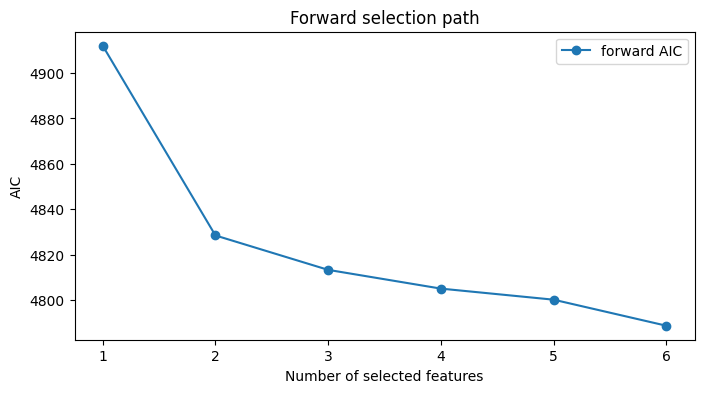

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(forward_history["step"], forward_history["score"], marker="o", label="forward AIC")
ax.set_xlabel("Number of selected features")
ax.set_ylabel("AIC")
ax.set_title("Forward selection path")
ax.legend()
plt.show()

## 5. Compare selection criteria

AIC, BIC, and adjusted $R^2$ can choose different subsets. BIC usually prefers fewer features than
AIC. Adjusted $R^2$ is scale-free but still in-sample.

In [9]:
criterion_rows = []
for criterion in ["aic", "bic", "adj_r2"]:
    features, _ = forward_selection(criterion)
    result = fit_ols(features)
    criterion_rows.append(
        {
            "criterion": criterion,
            "n_features": len(features),
            "features": ", ".join(features),
            "aic": result.aic,
            "bic": result.bic,
            "adjusted_r2": result.rsquared_adj,
        }
    )

pd.DataFrame(criterion_rows).set_index("criterion").round(3)

,n_features,features,aic,bic,adjusted_r2
criterion,,,,,
aic,6,"bmi, s5, bp, s1, sex, s2",4788.603,4817.243,0.508
bic,6,"bmi, s5, bp, s1, sex, s2",4788.603,4817.243,0.508
adj_r2,8,"bmi, s5, bp, s1, sex, s2, s4, s6",4790.241,4827.062,0.509


## 6. Honest evaluation with cross-validation

Stepwise selection uses the training data repeatedly, so the final in-sample AIC and $R^2$ are
optimistic. Cross-validation gives a more honest estimate of predictive performance. Compare:

- an intercept-only baseline;
- the full model;
- the selected model.

In [10]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def cv_rmse(features):
    model = make_pipeline(StandardScaler(), LinearRegression())
    scores = cross_val_score(
        model,
        X[features],
        y,
        cv=cv,
        scoring="neg_root_mean_squared_error",
    )
    return -scores.mean()


null_scores = cross_val_score(
    DummyRegressor(strategy="mean"),
    X,
    y,
    cv=cv,
    scoring="neg_root_mean_squared_error",
)
full_scores = cross_val_score(
    make_pipeline(StandardScaler(), LinearRegression()),
    X,
    y,
    cv=cv,
    scoring="neg_root_mean_squared_error",
)

cv_table = pd.DataFrame(
    {
        "model": ["null", "full", "forward_selected"],
        "cv_rmse": [-null_scores.mean(), -full_scores.mean(), cv_rmse(forward_features)],
        "n_features": [0, X.shape[1], len(forward_features)],
    }
).set_index("model")

cv_table.round(3)

,cv_rmse,n_features
model,,
null,77.193,0
full,54.849,10
forward_selected,54.549,6


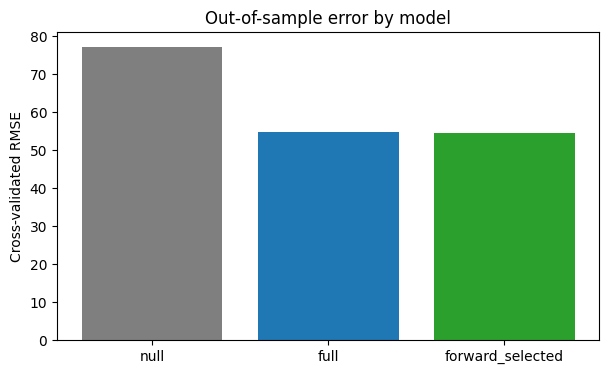

In [11]:
plt.figure(figsize=(7, 4))
plt.bar(cv_table.index, cv_table["cv_rmse"], color=["tab:grey", "tab:blue", "tab:green"])
plt.ylabel("Cross-validated RMSE")
plt.title("Out-of-sample error by model")
plt.show()

## 7. Inspect the selected model

The coefficient table is the part you would report. A coefficient is conditional on the other
features in the model, so removing a correlated feature can change the remaining coefficients.

In [12]:
selected_result = fit_ols(forward_features)
coefficient_table = pd.DataFrame(
    {
        "coefficient": selected_result.params,
        "std_error": selected_result.bse,
        "p_value": selected_result.pvalues,
        "ci_lower": selected_result.conf_int()[0],
        "ci_upper": selected_result.conf_int()[1],
    }
)
coefficient_table.round(4)

,coefficient,std_error,p_value,ci_lower,ci_upper
const,152.1335,2.5716,0.0000,147.0792,157.1878
bmi,529.8796,65.6202,0.0000,400.9076,658.8517
s5,804.1874,80.1730,0.0000,646.6127,961.7621
bp,327.2150,62.6932,0.0000,203.9958,450.4342
s1,-757.9303,160.4348,0.0000,-1073.2542,-442.6065
sex,-226.5066,59.8566,0.0002,-344.1508,-108.8625
s2,538.5797,146.7378,0.0003,250.1765,826.9828


The p-values above are the usual OLS p-values **conditional on the selected model**. Because the
model was chosen using the same data, they are not a valid correction for the selection process.
For confirmatory inference, use a pre-specified model, a hold-out set, or nested cross-validation.

## 8. Cautions

1. **Selection bias.** The selected model looks better than it will on new data because the data
   helped choose it.
2. **Instability.** Small changes in the data can change which features enter.
3. **Correlated features.** Stepwise may pick one of several equally good features arbitrarily.
4. **Invalid p-values.** Post-selection inference needs a correction or a fresh dataset.
5. **Not a causality tool.** A selected coefficient is an association, not a causal effect.

When the goal is prediction and the feature set is large, regularised regression (Ridge, Lasso,
ElasticNet) is often more stable than stepwise selection. When the goal is explanation, use domain
knowledge and pre-specified models.

## Summary

- Stepwise regression is a greedy subset search, not a guarantee of the best model.
- Forward, backward, and bidirectional variants can disagree.
- AIC/BIC/adjusted $R^2$ are in-sample criteria; cross-validation estimates out-of-sample error.
- Report the selected features, coefficients, uncertainty, and validation protocol together.
- Prefer regularisation or nested validation when selection instability matters.

## Exercises

1. Run all three selectors with BIC and compare the selected subsets.
2. Add a random noise feature to `X` and see how often stepwise selects it.
3. Compare the selected OLS model with `LassoCV` on the same data using nested cross-validation.
4. Repeat forward selection on 20 bootstrap samples and count how often each feature is selected.
5. Write a short paragraph explaining why a low AIC does not prove that a model is causally correct.